## Attention 

##### +20 frases de uma conversa real

In [ ]:
import numpy as np
from sentence_transformers import SentenceTransformer


sentences = [
    "João, seu cabra safado!!!",
    "Mas será possível? Será que nem aqui você me dá sossego capitão? Vige queta chegando mais, olha ali mais quatro que o senhor já despachou",
    "Falando nisso o que é que você ta fazendo aqui que não ta la em baixo?,"
    "Eu to morto que nem você",
    "Olha o respeito, e eu sou homem de morrer?",
    "O senhor não se lembra da história da gaita?",
    "É mesmo, e o que que o meu homem ta fazendo que não toca essa gaita?",
    "O leseira, Severino veio, besta",
    "Olha como fala comigo que eu te mato!!!",
    "ME MATAR COMO SE EU JÁ MORRI?",
    "Escuta aqui seu bixo froucho, você vai me pagar por essa historia da gaita!!!",
    "BIXO FROUCHO É SUA VÓ, Já morri mesmo, não vou ficar ouvindo desaforoe mais ninguém. Agora não tem pobre nem rico, valente nem froucho. Todo mundo igualdiante de Deus, OU DO DIABODiabo entra pela DIREITA com livro e chicote",
    "Diabo: Mas porque essas caras de espanto? Por acaso eu sou algum monstro?",
    "NÃOOO",
    "Não de jeito nenhum, estamos até impressionados com você beleza, com vossafinura...",
    "Parece até um artista",
    "E você acha mesmo é?",
    "Acho",
    "Então também acho",
    "Alguém já lhe disse que o senhor é muito mais simpático pessoalmente?",
    "Estão vendo... O diabo não é tão feio assim",
    "Pode ser, mas esse cheirinho de enxofre...",
    "Talvez o meu cheiro esteja incomodando vocês",
    "Nãoo... imagina",
    "Pois eu já estou à beira de ter uma pinura com esse fedor",
    "OOII? RESPEITO É BOM E EU GOSTO",
    "Você de graças a deus que o diabo é um cara bom, eu no lugar dele...",
    "Eu no lugar dele tomava era um banho com chá de amulece cacho que é praver se diminui essa nhaca",
    "VOCÊS AGORA VÃO PAGAR TUDO OQUE FIZERAM!!! VOU MANDAR TODOSPARA O 5° DOS INFERNOS, PARA PADECER COMIGO!!!",
    "QUE TRIBUNAL É ESSE QUE NÃO TEM APELAÇÃO? EU SEMPRE OUVIDIZER QUE PRA UMA PESSOA SER CONDENADA, ELA TEM QUE SER OUVIDA!!!",
]

sentences_e5 = [f"passage: {s}" for s in sentences]
model = SentenceTransformer('intfloat/multilingual-e5-base')

S = model.encode(sentences_e5)

print("\nEmbeddings (S):")
print(S.shape)
print(S)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10266.75it/s]
XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-base
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(59, 768)
[[ 0.00648403  0.02894126 -0.01443407 ... -0.04869791 -0.04151718
   0.01352753]
 [ 0.02048376  0.03003628 -0.02414208 ... -0.03564337 -0.04270871
   0.05704608]
 [ 0.00326279  0.02427406 -0.03647296 ... -0.03276005 -0.04986775
   0.04669476]
 ...
 [ 0.00532147  0.01940189 -0.04577983 ... -0.04003515 -0.04245349
   0.03765538]
 [ 0.01456064  0.00633073 -0.00372804 ... -0.03011508 -0.04220079
   0.00446096]
 [-0.0012877  -0.00044188 -0.01339891 ... -0.06365682 -0.03499099
   0.02179231]]


In [23]:
S = model.encode(sentences_e5, normalize_embeddings=False)

scores = np.dot(S, S.T)

n = len(sentences)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i:
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.8123458  0.         0.         ... 0.         0.         0.        ]
 [0.85336554 0.87836617 0.         ... 0.         0.         0.        ]
 ...
 [0.84533864 0.80076337 0.85116434 ... 0.         0.         0.        ]
 [0.84254086 0.80207235 0.85245818 ... 0.84172177 0.         0.        ]
 [0.84151769 0.80029482 0.82631469 ... 0.85079837 0.85930681 0.        ]]


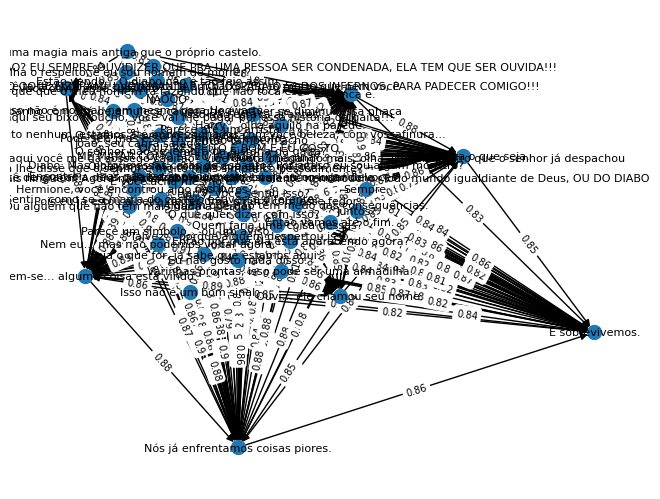

In [24]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences_e5):
    G.add_node(i, label=s)

for i in range(n):
    for j in range(n):
        weight = A[i, j]
        if weight > 0.2:
            G.add_edge(j, i, weight=weight)

pos = nx.spring_layout(G)

nx.draw(G, pos, node_size=100)

node_labels = {i: s for i, s in enumerate(sentences)}
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)

edge_labels = {k: round(v, 2) for k, v in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()

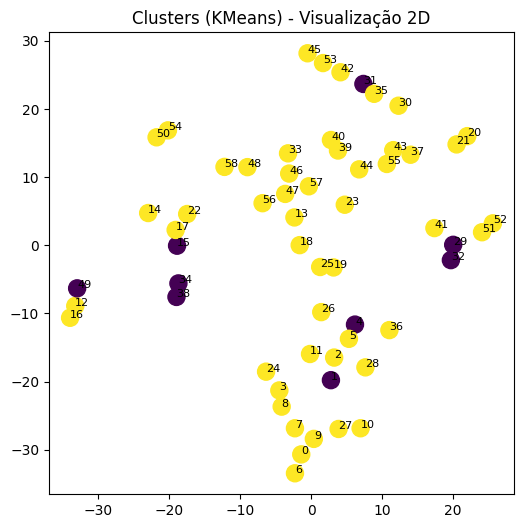

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

S_norm = normalize(S)

kmeans = KMeans(n_clusters=2, random_state=0)
labels = kmeans.fit_predict(S_norm)

tsne = TSNE(n_components=2, random_state=0, perplexity=5)
S_2d = tsne.fit_transform(S_norm)


plt.figure(figsize=(6,6))
plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=150)

for i in range(len(sentences)):
    plt.text(S_2d[i,0], S_2d[i,1], str(i), fontsize=8)

plt.title("Clusters (KMeans) - Visualização 2D")
plt.show()

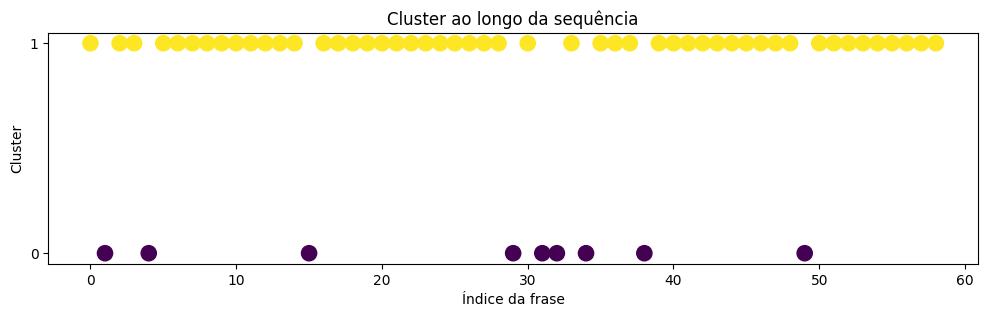

In [33]:
plt.figure(figsize=(12,3))
plt.scatter(range(len(sentences)), labels, c=labels, s=120)

plt.yticks([0,1])
plt.xlabel("Índice da frase")
plt.ylabel("Cluster")
plt.title("Cluster ao longo da sequência")

plt.show()

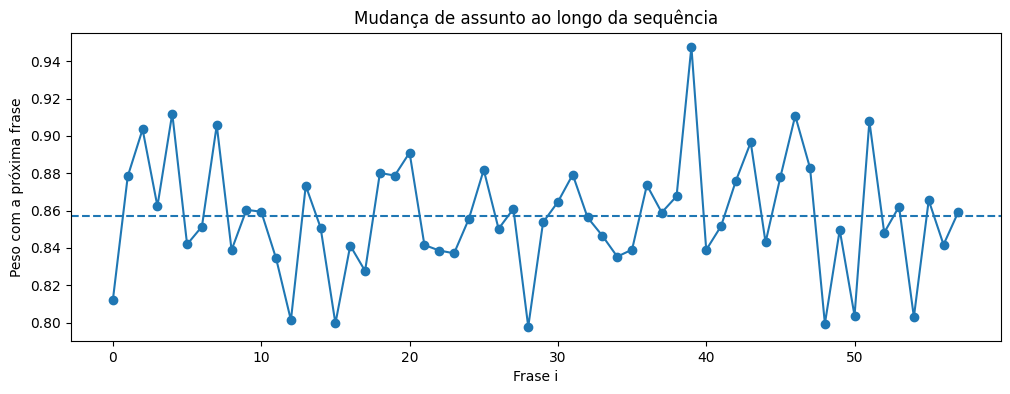

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

S_norm = normalize(S)

weights = np.array([
    cosine_similarity(S_norm[i].reshape(1, -1), S_norm[i+1].reshape(1, -1))[0, 0]
    for i in range(len(S_norm) - 1)
])


plt.figure(figsize=(12, 4))
plt.plot(weights, marker='o')
plt.axhline(np.mean(weights), linestyle='--')
plt.xlabel("Frase i")
plt.ylabel("Peso com a próxima frase")
plt.title("Mudança de assunto ao longo da sequência")
plt.show()

In [36]:
def cosine(a, b):
    return cosine_similarity(a.reshape(1, -1), b.reshape(1, -1))[0, 0]

k = 3  

pivot_scores = []

for i in range(k, len(S_norm) - k):
    prev_ctx = S_norm[i-k:i].mean(axis=0)
    next_ctx = S_norm[i+1:i+k+1].mean(axis=0)
    score = 1 - cosine(prev_ctx, next_ctx)
    pivot_scores.append((i, score))

pivot_scores.sort(key=lambda x: x[1], reverse=True)

print("Frases mais relevantes para mudança de rumo:")
for i, score in pivot_scores[:5]:
    print(f"\nÍndice {i} | score = {score:.4f}")
    print(sentences[i])

Frases mais relevantes para mudança de rumo:

Índice 29 | score = 0.0962
Harry, você sentiu isso?

Índice 48 | score = 0.0913
Então vamos até o fim.

Índice 28 | score = 0.0855
QUE TRIBUNAL É ESSE QUE NÃO TEM APELAÇÃO? EU SEMPRE OUVIDIZER QUE PRA UMA PESSOA SER CONDENADA, ELA TEM QUE SER OUVIDA!!!

Índice 47 | score = 0.0849
Seja o que for, já sabe que estamos aqui.

Índice 12 | score = 0.0843
NÃOOO
